**Set environment**

In [1]:
suppressMessages(suppressWarnings(source("../run_config_project_sing.R")))
show_env()

You are working on        Singularity: singularity_proj_encode_fcc 
BASE DIRECTORY (FD_BASE): /data/reddylab/Kuei 
REPO DIRECTORY (FD_REPO): /data/reddylab/Kuei/repo 
WORK DIRECTORY (FD_WORK): /data/reddylab/Kuei/work 
DATA DIRECTORY (FD_DATA): /data/reddylab/Kuei/data 

You are working with      ENCODE FCC 
PATH OF PROJECT (FD_PRJ): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC 
PROJECT RESULTS (FD_RES): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/results 
PROJECT SCRIPTS (FD_EXE): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/scripts 
PROJECT DATA    (FD_DAT): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/data 
PROJECT NOTE    (FD_NBK): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/notebooks 
PROJECT DOCS    (FD_DOC): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/docs 
PROJECT LOG     (FD_LOG): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/log 
PROJECT REF     (FD_REF): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/references 



## Prepare

**Set global variable**

In [2]:
vec = c(
    "fcc_astarr_macs_input_overlap",
    "fcc_astarr_macs_input_union"
)
names(vec) = vec

VEC_TXT_FOLDER = vec
for(txt in vec){cat(txt, "\n")}

fcc_astarr_macs_input_overlap 
fcc_astarr_macs_input_union 


In [3]:
TXT_FNAME_ANNOT = "region.annotation.hic_intact_deep.loop.anchor.tsv"

**View files**

In [4]:
txt_fdiry = file.path(FD_RES, "region_annotation", "*", "summary")
txt_fname = TXT_FNAME_ANNOT
txt_fglob = file.path(txt_fdiry, txt_fname)

vec = Sys.glob(txt_fglob)
for(txt in vec){cat(txt, "\n")}

/data/reddylab/Kuei/repo/Proj_ENCODE_FCC/results/region_annotation/fcc_astarr_macs_input_overlap/summary/region.annotation.hic_intact_deep.loop.anchor.tsv 
/data/reddylab/Kuei/repo/Proj_ENCODE_FCC/results/region_annotation/fcc_astarr_macs_input_union/summary/region.annotation.hic_intact_deep.loop.anchor.tsv 


## Import data

### Import region annotation

In [5]:
### loop to import data
lst = lapply(VEC_TXT_FOLDER, function(txt_folder){
    ### set file directory
    txt_fdiry = file.path(FD_RES, "region_annotation", txt_folder, "summary")
    txt_fname = TXT_FNAME_ANNOT
    txt_fpath = file.path(txt_fdiry, txt_fname)

    ### read table
    dat = read_tsv(txt_fpath, show_col_types = FALSE)
    return(dat)
})
names(lst) = VEC_TXT_FOLDER

### assign and show
lst_dat_region_annot_import = lst

res = lapply(lst, dim)
print(res)

dat = lst[[1]]
fun_display_table(head(dat, 3))

$fcc_astarr_macs_input_overlap
[1] 227729     26

$fcc_astarr_macs_input_union
[1] 252981     26



Chrom,ChromStart,ChromEnd,Region,Group,Label,Loop_Anchor,Loop,Size,Distance,Observed,ExpectedBL,ExpectedDonut,FdrBL,FdrDonut,LocalObserved,LocalPeakZ,LocalPval,Score_Log2OE,Zcore_Log2OE_by_Mean,Zcore_Log2OE_by_Median,Zcore_Log2OE_by_Mode,Dist_Log10,Dist_Bin,Zcore_Log2OE_by_DistStrat,Zcore_Log2OE_by_DistSmooth
chr1,778233,779389,chr1:778233-779389,hic_intact,Loop_A,chr1:778000-779000,chr1:778000-779000|chr1:827000-828000,1000,49000,16,2.803620,4.147049,1e-07,7.6e-06,8,2.234097,0.0208767,1.947915,0.0112455,0.1422544,0.3979698,4.690196,"[4.5,5)",0.5603609,0.5460845
chr1,869637,870233,chr1:869637-870233,hic_intact,Loop_A,chr1:870000-872000,chr1:870000-872000|chr1:974000-976000,2000,104000,31,10.256543,9.079411,1e-07,0.0e+00,6,4.898979,0.0000000,1.771598,-0.2596009,-0.1140001,0.1417154,5.017033,"[5,5.5)",-0.2752799,-0.3986085
chr1,869637,870233,chr1:869637-870233,hic_intact,Loop_A,chr1:870000-872000,chr1:870000-872000|chr1:1062000-1064000,2000,193000,24,5.239281,4.773047,0e+00,0.0e+00,5,4.472134,0.0000000,2.330052,0.5982581,0.6976415,0.9533570,5.285557,"[5,5.5)",0.6047244,0.5482221


## Summarize the loop strength by region

In [6]:
lst = lst_dat_region_annot_import
lst = lapply(lst, function(dat){
    ### summarize the loop scores and counts
    dat = dat %>% 
        dplyr::group_by(Chrom, ChromStart, ChromEnd, Region) %>%
        dplyr::summarise(
            Loop_Count = dplyr::n_distinct(Loop),
            Loop_Score_Mean = mean(Score_Log2OE, na.rm = TRUE),
            Loop_Score_Sum  =  sum(Score_Log2OE, na.rm = TRUE),
            Loop_Zcore_Global_Mean = mean(Zcore_Log2OE_by_Mode, na.rm = TRUE),
            Loop_Zcore_Global_Sum  =  sum(Zcore_Log2OE_by_Mode, na.rm = TRUE),
            Loop_Zcore_DistSm_Mean = mean(Zcore_Log2OE_by_DistSmooth, na.rm = TRUE),
            Loop_Zcore_DistSm_Sum  =  sum(Zcore_Log2OE_by_DistSmooth, na.rm = TRUE),
            .groups = "drop"
        )  
    
    return(dat)
})

### assign and show
lst_dat_region_annot_summary = lst

res = lapply(lst, dim)
print(res)

dat = lst[[1]]
fun_display_table(head(dat, 3))

$fcc_astarr_macs_input_overlap
[1] 53760    11

$fcc_astarr_macs_input_union
[1] 65084    11



Chrom,ChromStart,ChromEnd,Region,Loop_Count,Loop_Score_Mean,Loop_Score_Sum,Loop_Zcore_Global_Mean,Loop_Zcore_Global_Sum,Loop_Zcore_DistSm_Mean,Loop_Zcore_DistSm_Sum
chr1,778233,779389,chr1:778233-779389,1,1.947915,1.947915,0.3979698,0.3979698,0.5460845,0.5460845
chr1,826796,828040,chr1:826796-828040,1,1.947915,1.947915,0.3979698,0.3979698,0.5460845,0.5460845
chr1,869637,870233,chr1:869637-870233,4,1.938149,7.752596,0.3837763,1.5351050,-0.1816422,-0.7265690


**Explore: Count/Score distribution**

## Export results

In [7]:
for (txt_folder in VEC_TXT_FOLDER){

    ### get table
    dat_region_annot_result = lst_dat_region_annot_summary[[txt_folder]]
    
    ### set file directory
    txt_fdiry = file.path(
        FD_RES, 
        "region_annotation", 
        txt_folder,
        "summary"
    )
    
    ### write region annotation
    txt_fname = "region.annotation.hic_intact_deep.loop.score.node.tsv"
    txt_fpath = file.path(txt_fdiry, txt_fname)
    
    dat = dat_region_annot_result
    write_tsv(dat, txt_fpath)
}

**Explore: Differences between using mean and median**

In [50]:
lst = lst_dat_region_score_loop
lst = lapply(lst, function(dat){
    dat = dat %>% dplyr::mutate(Delta = (Loop_Log2OE_Median - Loop_Log2OE_Mean) / ((Loop_Log2OE_Median + Loop_Log2OE_Mean)/2))
    res = summary(dat$Delta)
    return(res)
})

print(lst)

ERROR: Error: object 'lst_dat_region_score_loop' not found


In [30]:
lst = lst_dat_region_annot_summary
lst = lapply(lst, function(dat){
    res = summary(dat$Loop_Zcore_Global)
    return(res)
})

print(lst)

$fcc_astarr_macs_input_overlap
    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
-1.25850 -0.38867  0.06724  0.12379  0.56991  5.23349 

$fcc_astarr_macs_input_union
    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
-1.25934 -0.44699  0.02797  0.09779  0.55495  5.28885 



In [31]:
lst = lst_dat_region_annot_summary
lst = lapply(lst, function(dat){
    res = summary(dat$Loop_Zcore_DistSm)
    return(res)
})

print(lst)

$fcc_astarr_macs_input_overlap
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
-2.5572 -1.0055 -0.3760 -0.3363  0.2540 10.9624 

$fcc_astarr_macs_input_union
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
-2.5572 -1.1097 -0.4455 -0.3910  0.2197 10.9624 



## Explore: count/score distribution

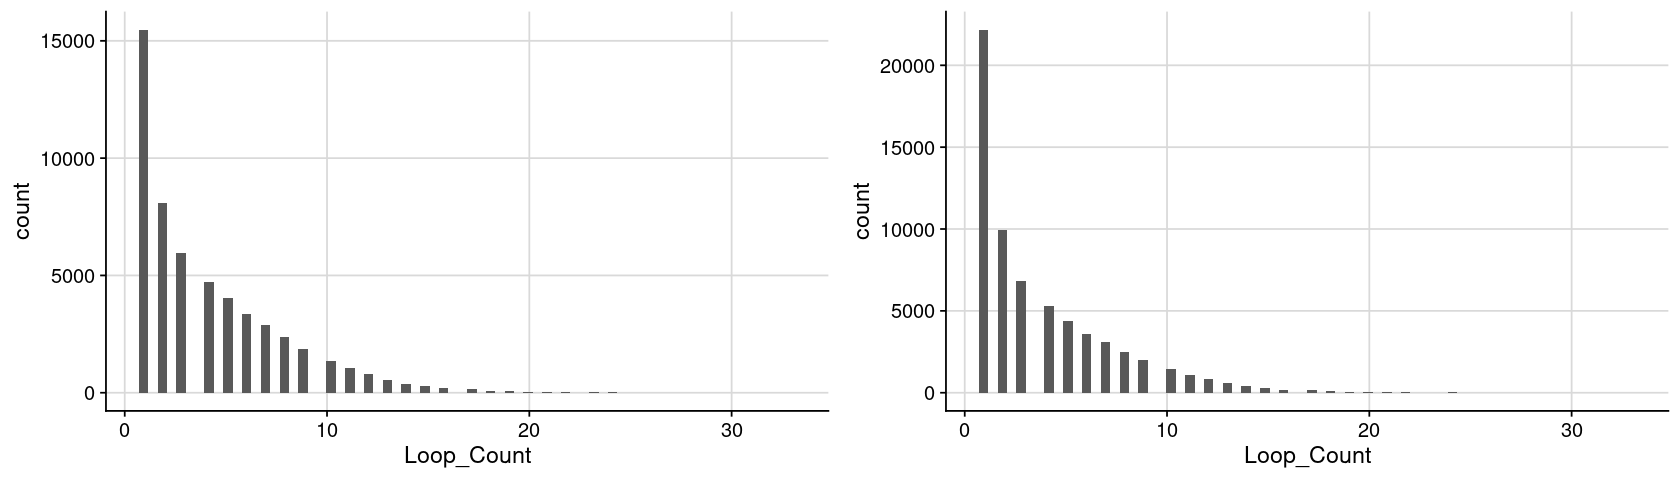

In [14]:
lst = lst_dat_region_annot_summary
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Loop_Count)) +
        geom_histogram(bins = 70) +
        theme_cowplot() +
        background_grid()
    return(gpt)
})

options(repr.plot.height=4, repr.plot.width=14)
plot_grid(plotlist = lst, nrow=1)

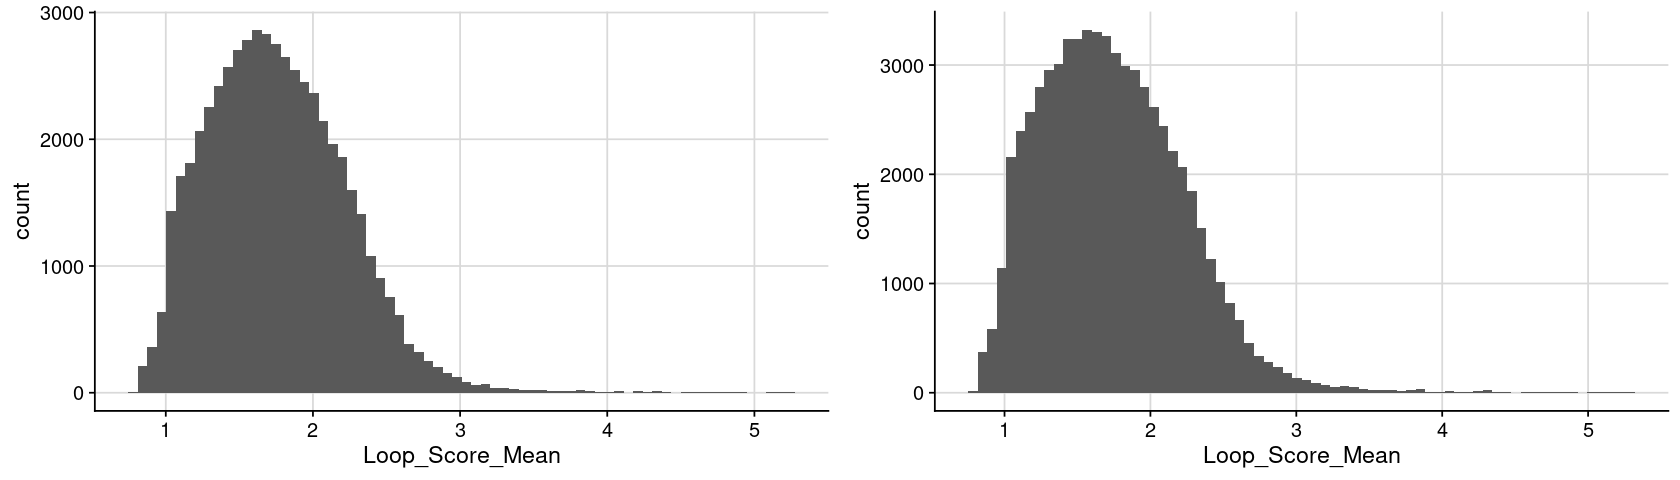

In [20]:
lst = lst_dat_region_annot_summary
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Loop_Score_Mean)) +
        geom_histogram(bins = 70) +
        theme_cowplot() +
        background_grid()
    return(gpt)
})

options(repr.plot.height=4, repr.plot.width=14)
plot_grid(plotlist = lst, nrow=1)

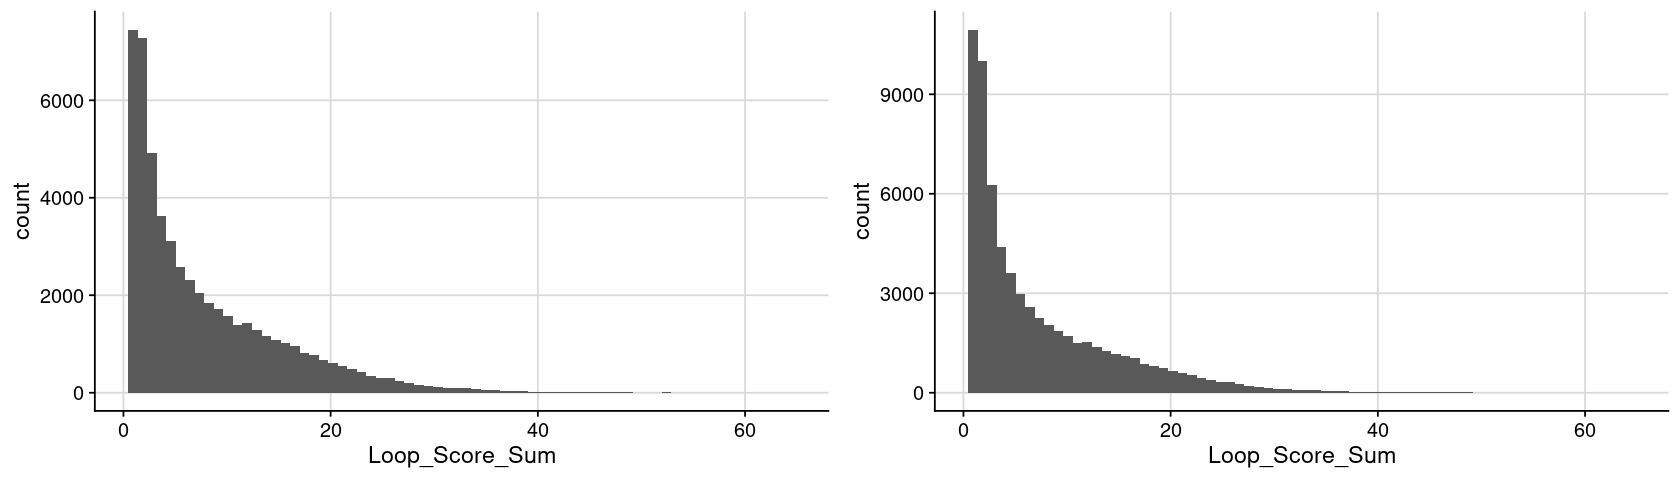

In [21]:
lst = lst_dat_region_annot_summary
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Loop_Score_Sum)) +
        geom_histogram(bins = 70) +
        theme_cowplot() +
        background_grid()
    return(gpt)
})

options(repr.plot.height=4, repr.plot.width=14)
plot_grid(plotlist = lst, nrow=1)

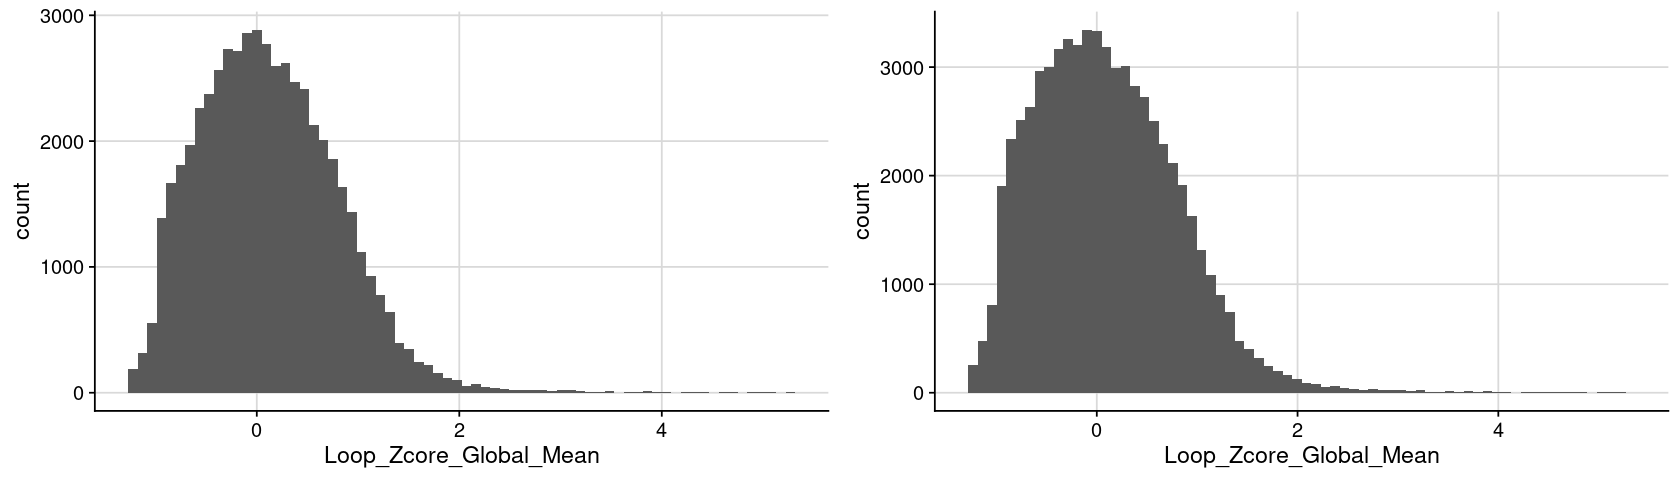

In [22]:
lst = lst_dat_region_annot_summary
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Loop_Zcore_Global_Mean)) +
        geom_histogram(bins = 70) +
        theme_cowplot() +
        background_grid()
    return(gpt)
})

options(repr.plot.height=4, repr.plot.width=14)
plot_grid(plotlist = lst, nrow=1)

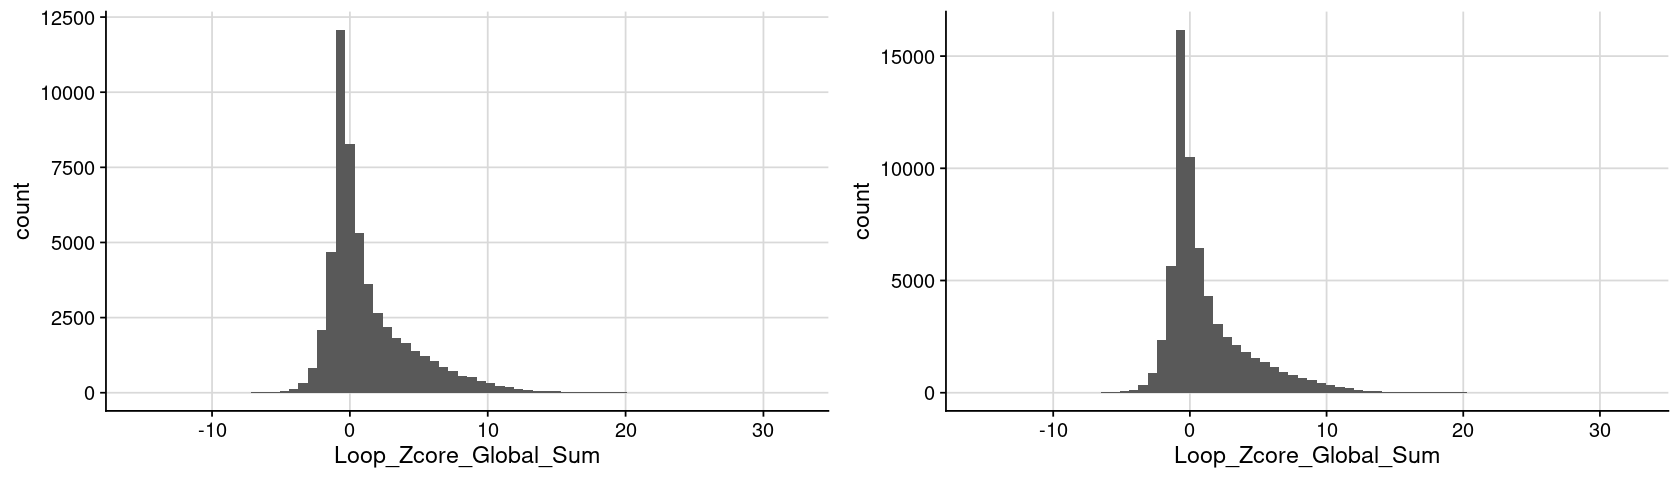

In [23]:
lst = lst_dat_region_annot_summary
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Loop_Zcore_Global_Sum)) +
        geom_histogram(bins = 70) +
        theme_cowplot() +
        background_grid()
    return(gpt)
})

options(repr.plot.height=4, repr.plot.width=14)
plot_grid(plotlist = lst, nrow=1)

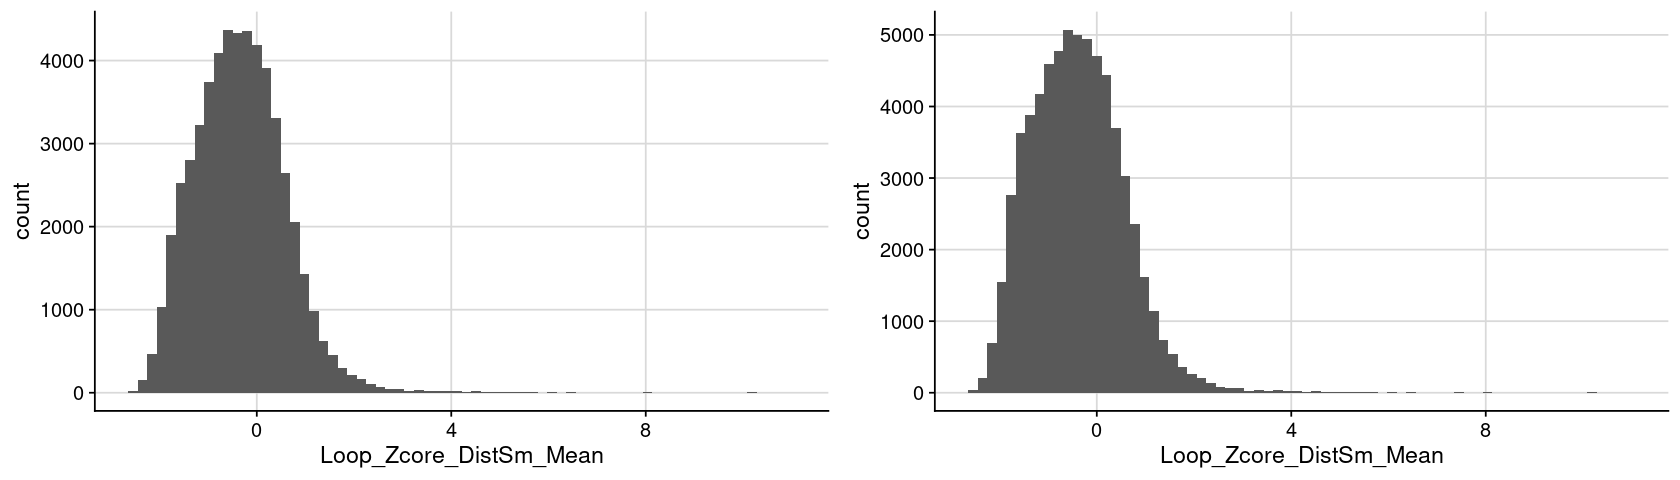

In [17]:
lst = lst_dat_region_annot_summary
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Loop_Zcore_DistSm_Mean)) +
        geom_histogram(bins = 70) +
        theme_cowplot() +
        background_grid()
    return(gpt)
})

options(repr.plot.height=4, repr.plot.width=14)
plot_grid(plotlist = lst, nrow=1)

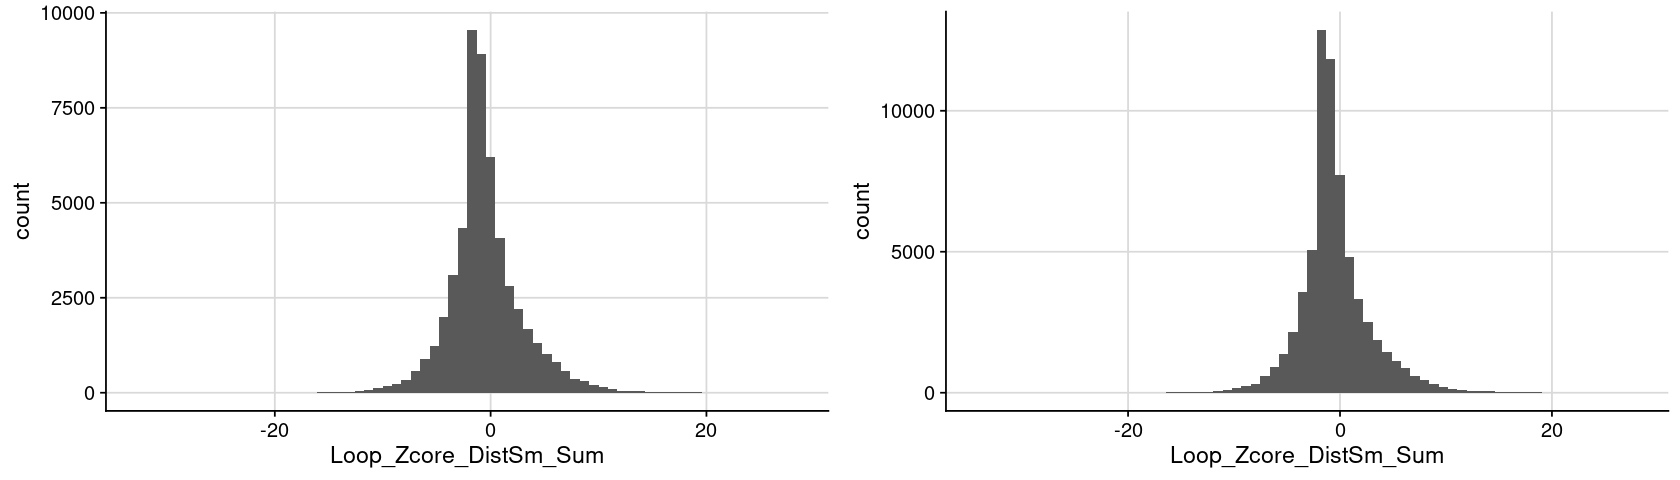

In [18]:
lst = lst_dat_region_annot_summary
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Loop_Zcore_DistSm_Sum)) +
        geom_histogram(bins = 70) +
        theme_cowplot() +
        background_grid()
    return(gpt)
})

options(repr.plot.height=4, repr.plot.width=14)
plot_grid(plotlist = lst, nrow=1)

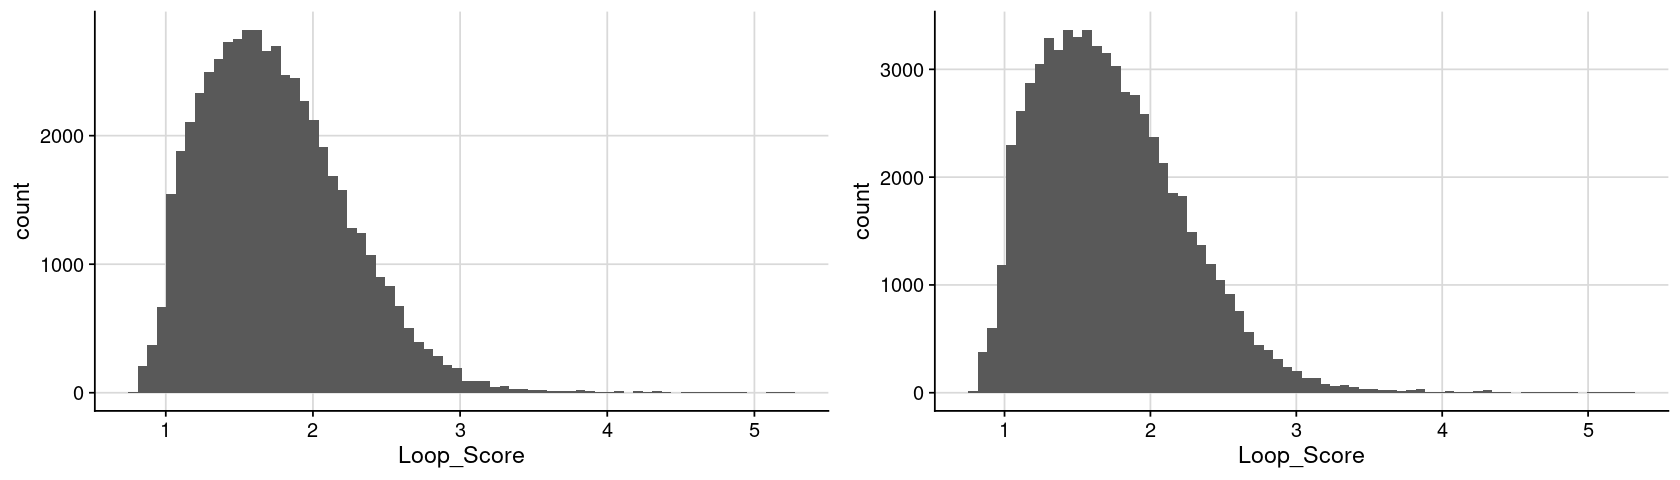

In [40]:
lst = lst_dat_region_annot_summary
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Loop_Score)) +
        geom_histogram(bins = 70) +
        theme_cowplot() +
        background_grid()
    return(gpt)
})

options(repr.plot.height=4, repr.plot.width=14)
plot_grid(plotlist = lst, nrow=1)

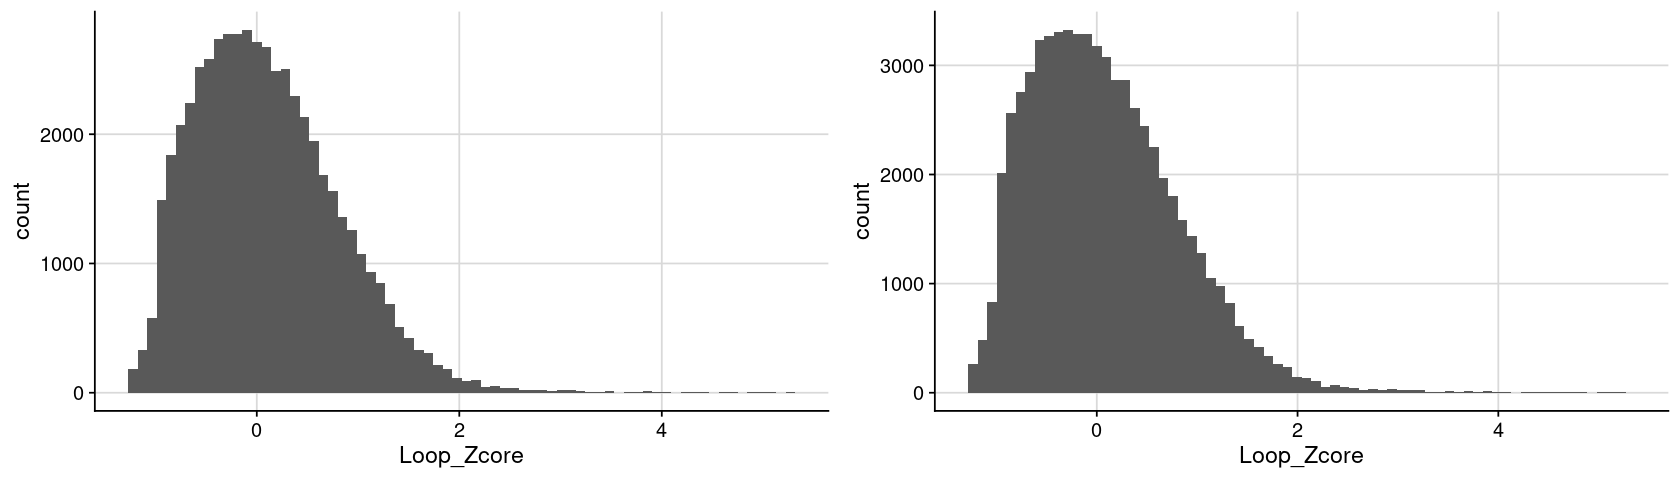

In [41]:
lst = lst_dat_region_annot_summary
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Loop_Zcore)) +
        geom_histogram(bins = 70) +
        theme_cowplot() +
        background_grid()
    return(gpt)
})

options(repr.plot.height=4, repr.plot.width=14)
plot_grid(plotlist = lst, nrow=1)

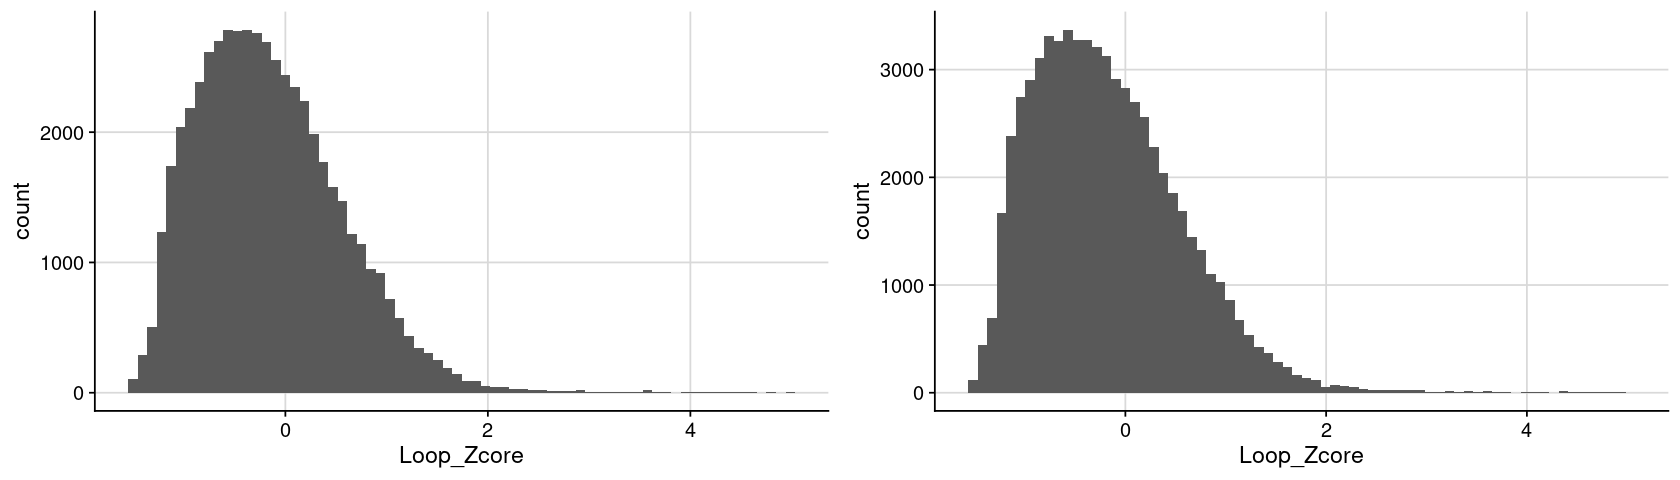

In [43]:
lst = lst_dat_region_annot_summary
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Loop_Zcore)) +
        geom_histogram(bins = 70) +
        theme_cowplot() +
        background_grid()
    return(gpt)
})

options(repr.plot.height=4, repr.plot.width=14)
plot_grid(plotlist = lst, nrow=1)

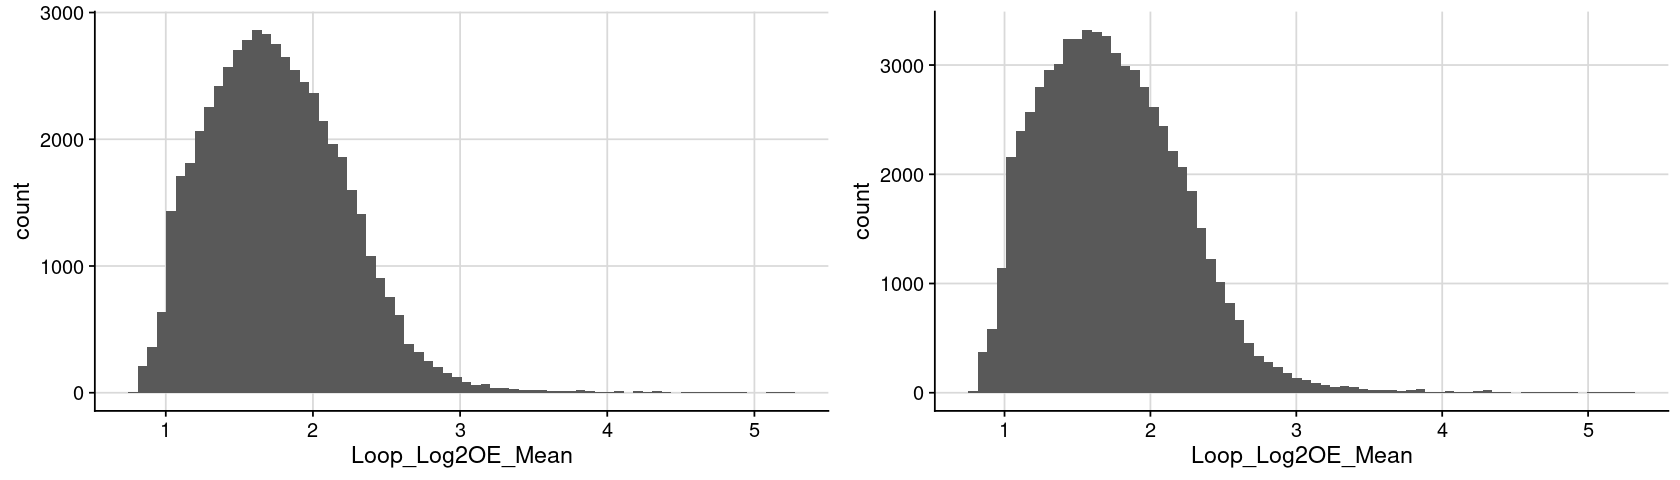

In [63]:
lst = lst_dat_region_score_loop
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Loop_Log2OE_Mean)) +
        geom_histogram(bins = 70) +
        theme_cowplot() +
        background_grid()
    return(gpt)
})

options(repr.plot.height=4, repr.plot.width=14)
plot_grid(plotlist = lst, nrow=1)

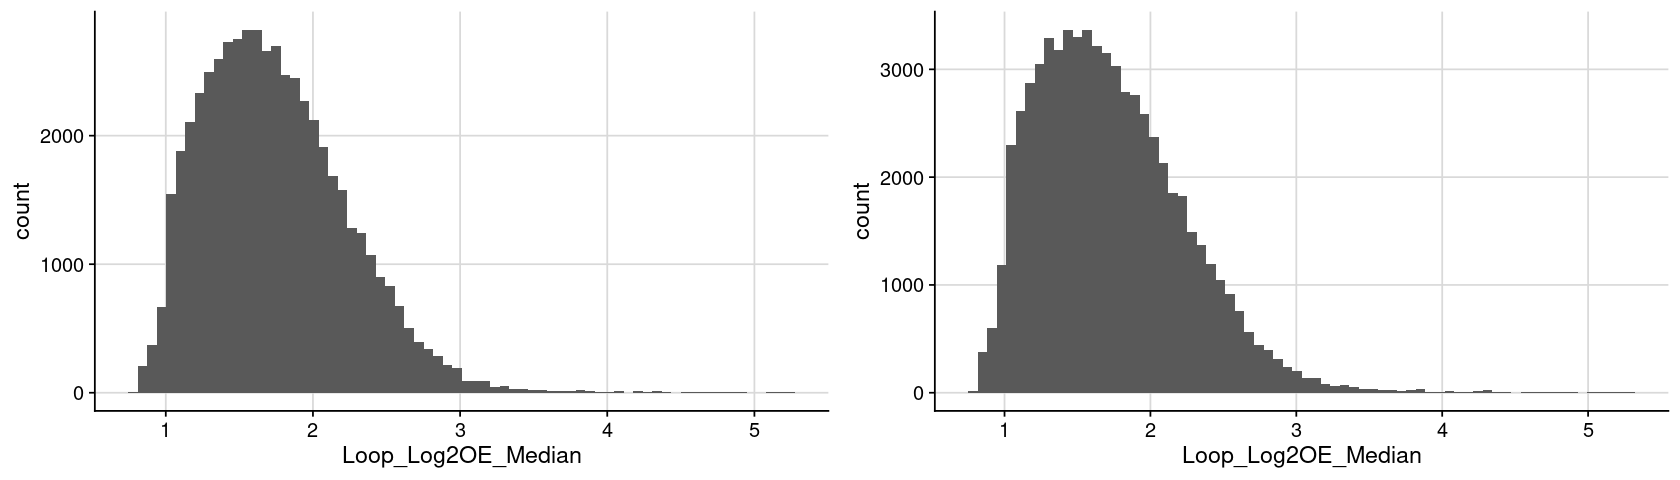

In [64]:
lst = lst_dat_region_score_loop
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Loop_Log2OE_Median)) +
        geom_histogram(bins = 70) +
        theme_cowplot() +
        background_grid()
    return(gpt)
})

options(repr.plot.height=4, repr.plot.width=14)
plot_grid(plotlist = lst, nrow=1)

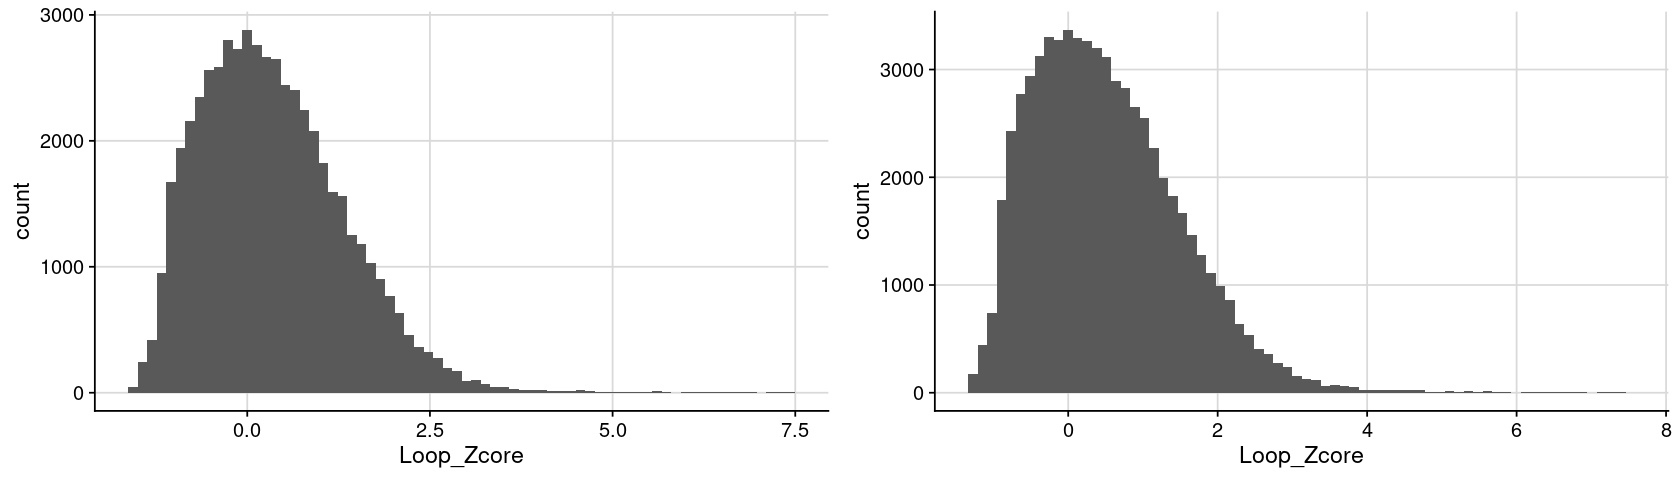

In [65]:
lst = lst_dat_region_score_loop
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Loop_Zcore)) +
        geom_histogram(bins = 70) +
        theme_cowplot() +
        background_grid()
    return(gpt)
})

options(repr.plot.height=4, repr.plot.width=14)
plot_grid(plotlist = lst, nrow=1)

```
Left panel (raw scores): shows the raw distribution of your Loop_Score.

Red dashed line = median.

Blue dashed line = mode estimate from kernel density.

Right panel (robust z-scores): shows the distribution after (x − mode)/MAD.

Blue dashed line = 0 (the shifted peak).

If things worked correctly, the histogram peak should now sit very close to zero.
```

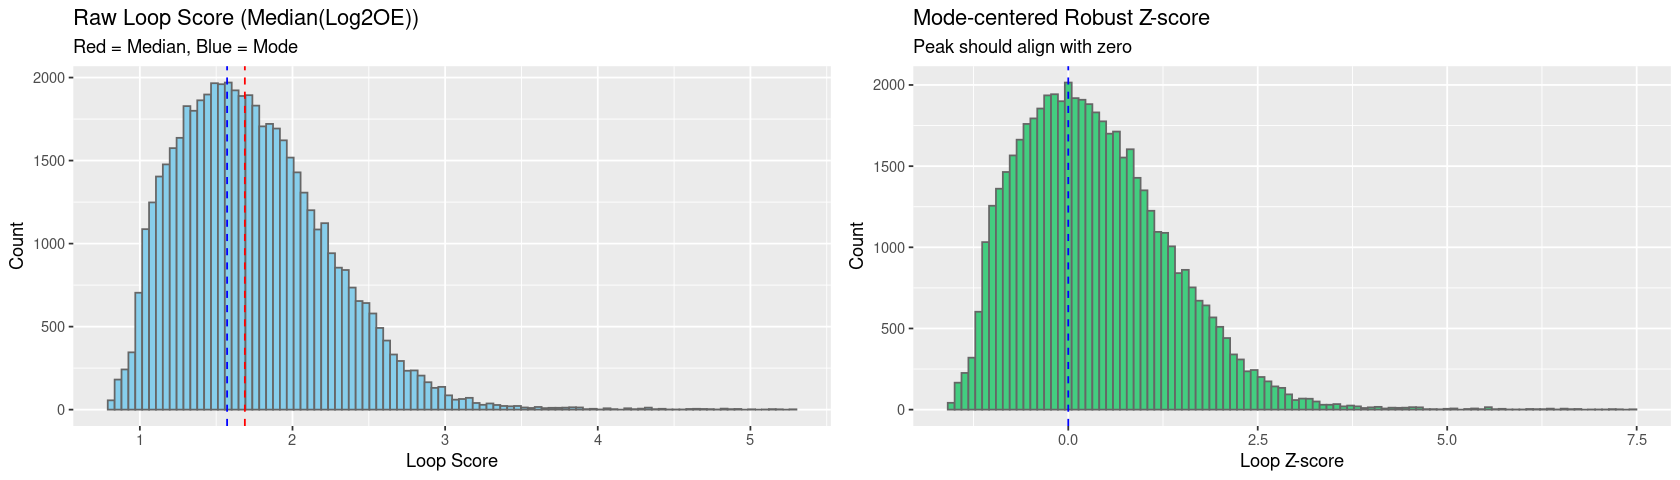

In [67]:
dat <- lst_dat_region_score_loop[[1]]  # pick one dataset

# Histogram of raw scores
p1 <- ggplot(dat, aes(x = Loop_Score)) +
  geom_histogram(bins = 100, fill = "skyblue", color = "grey40") +
  geom_vline(aes(xintercept = median(Loop_Score, na.rm = TRUE)),
             color = "red", linetype = "dashed") +
  geom_vline(aes(xintercept = density(Loop_Score)$x[which.max(density(Loop_Score)$y)]),
             color = "blue", linetype = "dashed") +
  labs(title = "Raw Loop Score (Median(Log2OE))",
       subtitle = "Red = Median, Blue = Mode",
       x = "Loop Score", y = "Count")

# Histogram of z-scores (mode-centered, MAD-scaled)
p2 <- ggplot(dat, aes(x = Loop_Zcore)) +
  geom_histogram(bins = 100, fill = "seagreen3", color = "grey40") +
  geom_vline(xintercept = 0, color = "blue", linetype = "dashed") +
  labs(title = "Mode-centered Robust Z-score",
       subtitle = "Peak should align with zero",
       x = "Loop Z-score", y = "Count")

# Show side by side
plot_grid(p1, p2, nrow=1)

## Export results

In [68]:
for (txt_folder in VEC_TXT_FOLDER){

    ### get table
    dat_region_annot_result = lst_dat_region_score_loop[[txt_folder]]
    
    ### set file directory
    txt_fdiry = file.path(
        FD_RES, 
        "region_annotation", 
        txt_folder,
        "summary"
    )
    
    ### write region annotation
    txt_fname = "region.annotation.hic_intact_deep.loop.score.tsv"
    txt_fpath = file.path(txt_fdiry, txt_fname)
    
    dat = dat_region_annot_result
    write_tsv(dat, txt_fpath)
}